# *Vasicek vs. CIR Interest Rate Stress Testing*

## *Short-Rate Models, Monte Carlo Simulation, and Model Risk*

## *1. Project Objective*

In this project, I compare the Vasicek and the Cox–Ingersoll–Ross (CIR) models with a particular focus on their behaviour under stressed interest-rate volatility.

The analysis examines how the structural differences between the two models affect:

- the simulated evolution and distribution of short-term interest rates;
- the occurrence and severity of negative interest rates;
- CIR model behaviour and the Feller condition;
- Euler–Maruyama simulation and its accuracy;
- the distribution and tail behaviour of simulated rates;
- the resulting discount factors and model-implied bond valuations; and
- the sensitivity of these results to increasing interest-rate volatility.

The broader objective is to illustrate how different modelling assumptions result in materially different risk and valuation outcomes. This highlights the importance of model selection and model risk in quantitative finance.

## 2. *Research Questions*

The analysis aims to answer the following questions:

1. How accurately does the Euler–Maruyama method approximate the Vasicek model when compared with its exact transition distribution?

2. How do the Vasicek and CIR models differ in their treatment of low and negative interest rates?

3. What is the effect of violating the CIR Feller condition on simulated interest-rate paths?

4. How does increasing interest-rate volatility affect the distribution and tail behaviour of simulated short rates?

5. How do differences in simulated interest-rate dynamics translate into differences in discount factors and bond valuations?

6. What do these results imply about the strengths, limitations, and model-risk characteristics of the Vasicek and CIR frameworks?

## 3. *Model Setup*

## 3.1 *Model Parameters and Assumptions*

The baseline parameters used throughout the analysis are shown below. The initial short rate is set at 4%, while the long-run interest rate is 5%. The mean-reversion parameter controls the speed at which the short rate tends to return toward its long-run level.

I use a baseline volatility of 7%. A substantially higher volatility of 20% is subsequently introduced as a stress scenario to examine how the models behave under adverse conditions.

The simulation horizon is 10 years, divided into 1,000 time steps. Monte Carlo analyses later in the project use 10,000 simulated interest-rate paths.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Model parameters

r0 = 0.04       # Initial short rate: 4%
a = 0.15        # Speed of mean reversion
b = 0.05        # Long-run short rate: 5%
sigma = 0.07    # Baseline volatility: 7%

T = 10          # Simulation horizon: 10 years
N = 1000        # Number of time steps
dt = T/N      # Length of each time step

M = 10000       # Number of Monte Carlo paths

# Reproducibility
np.random.seed(42)

## 3.2 *Parameter Interpretation*

The parameter $a$ determines the speed of mean reversion: larger values cause interest rates to move more rapidly toward the long-run mean $b$. The volatility parameter $\sigma$ controls the magnitude of random shocks to the short rate.

The baseline and stressed volatility assumptions are illustrative rather than calibrated to a specific market yield curve. Consequently, the results should be interpreted as a model-comparison and stress-testing exercise rather than as forecasts of actual future interest rates.

The random seed is fixed so that the stochastic simulations are reproducible. This allows the analysis to be replicated and the results to be compared consistently when the code is rerun.

# 4. *Vasicek Model*

## 4.1 *Model Specification*

The Vasicek model describes the evolution of the instantaneous short-term interest rate as a mean-reverting stochastic process:

$$
dr_t = a(b-r_t)\,dt + \sigma\,dW_t
$$

where:

- $r_t$ is the instantaneous short rate at time $t$;
- $a$ is the speed of mean reversion;
- $b$ is the long-run mean interest rate;
- $\sigma$ is the volatility of the short rate; and
- $W_t$ is a standard Wiener process.

The model assumes that the short rate is normally distributed. Consequently, unlike models with a non-negative state space, the Vasicek model permits interest rates to become negative.

## 4.2 *Euler – Maruyama Simulation*

The Euler–Maruyama method provides a numerical approximation to the solution of a stochastic differential equation. For a time step $\Delta t$, the Vasicek SDE can be discretized as:

$$
r_{t+\Delta t}
=
r_t
+
a(b-r_t)\Delta t
+
\sigma\sqrt{\Delta t}\,Z_t,
$$

where $Z_t\sim N(0,1)$.

Although the Vasicek model has an exact transition distribution, Euler–Maruyama is used here to demonstrate a general numerical approach to simulating SDEs. The exact Vasicek transition will subsequently be used as a benchmark for evaluating the numerical approximation.

In [2]:
# Time grid and initialisation
t = np.linspace(0, T, N + 1)
r_vasicek_euler = np.zeros(N + 1)
r_vasicek_euler[0] = r0

# Generate independent standard normal shocks
Z = np.random.normal(0, 1, N)
Z_bridge = np.random.normal(0, 1, N)

# Euler–Maruyama simulation
for i in range(1, N + 1):
    dW = np.sqrt(dt) * Z[i - 1]
    r_vasicek_euler[i] = (r_vasicek_euler[i - 1] + a*(b - r_vasicek_euler[i - 1])*dt + sigma*dW)

## 4.3 *Visualising the Euler–Maruyama Path*

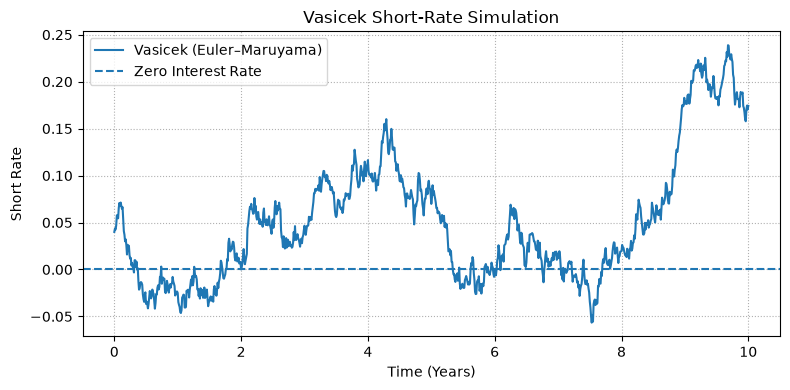

In [3]:
plt.figure(figsize=(8,4))
plt.plot(t,r_vasicek_euler,label="Vasicek (Euler–Maruyama)")
plt.axhline(0,linestyle="--",label="Zero Interest Rate")
plt.title("Vasicek Short-Rate Simulation")
plt.xlabel("Time (Years)")
plt.ylabel("Short Rate")
plt.legend()
plt.grid(True, linestyle=":")
plt.tight_layout()
plt.show()

***Interpretation:*** The simulated short rate fluctuates around the long-run mean of 5%, illustrating the mean-reverting property of the Vasicek model. Because the model assumes normally distributed interest rates, the simulated path can move below zero. The occurrence of negative rates is therefore a structural characteristic of the model rather than a numerical error.

## 4.4 *Exact Vasicek Simulation*

The Vasicek model has an analytical solution. This allows its transition distribution to be simulated directly without using a numerical approximation such as Euler–Maruyama.

For a time interval $\Delta t$, the exact transition is:

$$
r_{t+\Delta t}
=
r_t e^{-a\Delta t}
+
b\left(1-e^{-a\Delta t}\right)
+
\sigma
\sqrt{\frac{1-e^{-2a\Delta t}}{2a}}Z_t,
$$

where $Z_t\sim N(0,1)$.

The exact simulation provides a benchmark against which the Euler–Maruyama approximation can be evaluated.

In [4]:
# Exact Vasicek simulation
r_vasicek_exact = np.zeros(N + 1)
r_vasicek_exact[0] = r0

# Precompute exact transition coefficients
decay = np.exp(-a*dt)
var_exact = (1 - decay**2)/(2*a)
cov_exact = (1 - decay)/a
conditional_std = np.sqrt(var_exact - cov_exact**2/dt)

# Exact simulation using Brownian-increment coupling
for i in range(1, N + 1):
    exact_innovation = ((cov_exact/np.sqrt(dt))*Z[i - 1] + conditional_std*Z_bridge[i - 1])
    r_vasicek_exact[i] = (r_vasicek_exact[i - 1]*decay + b*(1 - decay) + sigma*exact_innovation)

## 4.5 *Euler–Maruyama vs. Exact Solution*

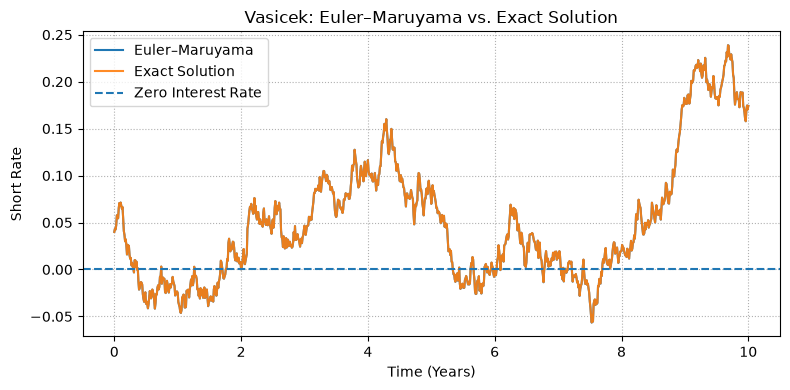

In [5]:
plt.figure(figsize=(8,4))
plt.plot(t,r_vasicek_euler,label="Euler–Maruyama")
plt.plot(t,r_vasicek_exact,label="Exact Solution",alpha=0.9)
plt.axhline(0,linestyle="--",label="Zero Interest Rate")
plt.title("Vasicek: Euler–Maruyama vs. Exact Solution")
plt.xlabel("Time (Years)")
plt.ylabel("Short Rate")
plt.legend()
plt.grid(True, linestyle=":")
plt.tight_layout()
plt.show()

## 4.6 *Numerical Approximation Error*
The two simulations are coupled through the same underlying Brownian increments. Euler–Maruyama uses these increments directly, while the exact Vasicek transition incorporates the corresponding Brownian-bridge component to account for the evolution of the process within each time step. This allows the difference between the simulated paths at the grid points to provide a meaningful measure of the Euler–Maruyama discretisation error.

The following metrics quantify the difference:

- **Maximum absolute error**
- **Mean absolute error**
- **Root mean squared error (RMSE)**

In [6]:
# Calculate approximation errors
error = r_vasicek_euler - r_vasicek_exact
max_error = np.max(np.abs(error))
mean_abs_error = np.mean(np.abs(error))
rmse = np.sqrt(np.mean(error**2))

print(f"Maximum absolute error: {max_error:.6f}")
print(f"Mean absolute error:    {mean_abs_error:.6f}")
print(f"RMSE:                   {rmse:.6f}")

Maximum absolute error: 0.000191
Mean absolute error:    0.000077
RMSE:                   0.000090


### ***Interpretation***

The approximation produces very small deviations from the exact Vasicek simulation. The mean absolute error is approximately **0.77 basis points**, while the RMSE is approximately **0.9 basis points** and the maximum absolute error is **1.91 basis points**.

Relative to the level of interest rates being modelled, these errors are small, suggesting that Euler–Maruyama provides a close numerical approximation to the exact Vasicek solution at the chosen time-step size. However, this result reflects the particular parameterization and discretisation used in the simulation; it should not be interpreted as evidence that Euler–Maruyama will always produce errors of this magnitude.

## 4.7 *Convergence Analysis*

Euler–Maruyama is a numerical approximation of the continuous-time Vasicek process. Its accuracy depends partly on the size of the time step, $\Delta t$.

To examine convergence, the Euler–Maruyama simulation is repeated using progressively finer time grids. A single Brownian path is used across all grid sizes, ensuring that differences in approximation errors are attributable to changes in time discretisation rather than independent random shocks. The resulting numerical approximations are compared with the exact Vasicek solution at corresponding time points.

As $\Delta t$ becomes smaller, we expect the numerical approximation to become more accurate and the error relative to the exact solution to decrease.

In [7]:
# Convergence analysis using a common Brownian path
N_values = [100, 250, 500, 1000, 2500, 5000]

N_fine = max(N_values)
dt_fine = T/N_fine

# Generate Brownian increments on the finest grid
Z_fine = np.random.normal(0, 1, N_fine)
Z_bridge = np.random.normal(0, 1, N_fine)
dW_fine = np.sqrt(dt_fine)*Z_fine

# Construct the exact Vasicek path on the finest grid
r_exact_fine = np.zeros(N_fine + 1)
r_exact_fine[0] = r0

decay_fine = np.exp(-a*dt_fine)
var_exact = (1 - decay_fine**2)/(2*a)
cov_exact = (1 - decay_fine)/a
conditional_std = np.sqrt(var_exact - cov_exact**2/dt_fine)

for i in range(1, N_fine + 1):
    exact_innovation = ((cov_exact/np.sqrt(dt_fine))*Z_fine[i - 1] + conditional_std*Z_bridge[i - 1])
    r_exact_fine[i] = (r_exact_fine[i - 1]*decay_fine + b*(1 - decay_fine) + sigma*exact_innovation)


# Compare Euler–Maruyama simulations at different grid sizes
max_errors = []
mean_abs_errors = []
rmses = []

for N_test in N_values:
    m = N_fine//N_test
    dt_test = T/N_test

    # Aggregate fine-grid Brownian increments
    dW_coarse = dW_fine.reshape(N_test, m).sum(axis=1)

    # Euler–Maruyama path
    r_euler = np.zeros(N_test + 1)
    r_euler[0] = r0

    for i in range(1, N_test + 1):
        r_euler[i] = (r_euler[i - 1] + a*(b - r_euler[i - 1])*dt_test + sigma*dW_coarse[i - 1])

    # Extract exact values at the corresponding coarse-grid points
    r_exact = r_exact_fine[::m]

    # Calculate approximation errors
    error = r_euler - r_exact

    max_errors.append(np.max(np.abs(error)))
    mean_abs_errors.append(np.mean(np.abs(error)))
    rmses.append(np.sqrt(np.mean(error**2)))

In [8]:
# Display convergence results
print("N      dt          Max Error       Mean Abs Error       RMSE")

for i,N_test in enumerate(N_values):
    dt_test = T/N_test
    print(f"{N_test:<7}"
        f"{dt_test:<12.6f}"
        f"{max_errors[i]:<16.8f}"
        f"{mean_abs_errors[i]:<21.8f}"
        f"{rmses[i]:.8f}")

N      dt          Max Error       Mean Abs Error       RMSE
100    0.100000    0.00169205      0.00058932           0.00069102
250    0.040000    0.00052159      0.00016877           0.00020068
500    0.020000    0.00033859      0.00013742           0.00016105
1000   0.010000    0.00015111      0.00005011           0.00005901
2500   0.004000    0.00006302      0.00002564           0.00002916
5000   0.002000    0.00003200      0.00001305           0.00001534


### *Interpretation*
The convergence analysis examines how the Euler–Maruyama approximation changes as the time step $\Delta t$ becomes progressively smaller. By using a common underlying Brownian path across all grid sizes, the comparison isolates the effect of time discretisation more effectively.

The results show a consistent reduction in approximation error as the number of time steps increases. In particular, RMSE decreases from ***0.00069102*** at \(N=100\) to ***0.00001534*** at \(N=5,000\). This provides empirical evidence that the Euler–Maruyama approximation converges toward the exact Vasicek solution as the time discretisation becomes finer.

## 4.8 *Convergence Plot*

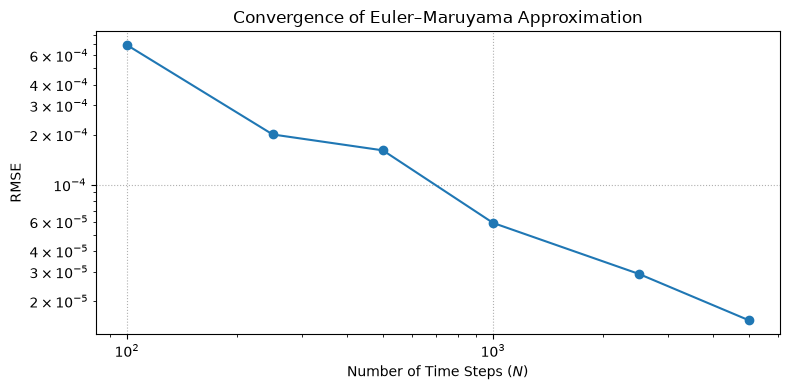

In [9]:
plt.figure(figsize=(8,4))
plt.loglog(N_values,rmses,marker="o")
plt.xlabel("Number of Time Steps ($N$)")
plt.ylabel("RMSE")
plt.title("Convergence of Euler–Maruyama Approximation")
plt.grid(True, linestyle=":")
plt.tight_layout()
plt.show()

### ***Interpretation***
The plot shows a consistent decline in RMSE as the number of time steps increases. This indicates that reducing the time step generally improves the accuracy of the Euler–Maruyama approximation relative to the exact solution.

The results exhibit a monotonic reduction in approximation error across all the grid sizes examined. This provides further empirical evidence that the Euler–Maruyama approximation converges toward the exact solution as the time discretisation becomes finer.

# 5. *CIR Model*

## 5.1 *Model Specification*

The Cox–Ingersoll–Ross (CIR) model describes the evolution of the short-term interest rate according to the stochastic differential equation

$$
dr_t = a(b-r_t)\,dt + \sigma\sqrt{r_t}\,dW_t,
$$

where:

- $r_t$ is the short-term interest rate at time $t$.
- $a$ is the speed of mean reversion.
- $b$ is the long-run mean interest rate.
- $\sigma$ is the volatility parameter.
- $W_t$ is a Wiener process.

Unlike the Vasicek model, the volatility term is proportional to $\sqrt{r_t}$. Consequently, volatility decreases as the interest rate approaches zero, which helps the CIR model maintain non-negative interest
rates.

The Feller condition

$$
2ab \geq \sigma^2
$$
provides a sufficient condition for the CIR process to remain strictly
positive.

## 5.2 Partial-Truncation Euler–Maruyama Simulation
The CIR process is simulated numerically using an Euler–Maruyama scheme with a partial-truncation adjustment.

For a time step $\Delta t$, the discretisation is given by
$$
r_{n + 1}
=
r_n+a(b-r_n^+)\Delta t
+\sigma\sqrt{r_n^+}\sqrt{\Delta t}Z_n,
$$

where
$$
r_n^+=\max(r_n,0),
\qquad Z_n\sim N(0,1).
$$

The positive-part adjustment is applied to the previous short rate in both the drift and diffusion coefficients. This ensures that the square-root term is well-defined and prevents negative values from entering the coefficient calculations.

However, the original rate $r_n$ is retained in the first term of the update. Consequently, the scheme does not guarantee non-negative simulated rates.
Any negative values produced by this numerical implementation should therefore be distinguished from the theoretical behaviour of the continuous-time CIR process.

In [10]:
# CIR Partial-Truncation Euler–Maruyama simulation
r_cir = np.zeros(N + 1)
r_cir[0] = r0

for i in range(1, N + 1):
    r_cir_prev = max(r_cir[i - 1], 0)
    dW = Z[i - 1]*np.sqrt(dt)
    r_cir[i] = (r_cir[i - 1] + a*(b - r_cir_prev)*dt + sigma*np.sqrt(r_cir_prev)*dW)

## 5.3 *Visualising the Euler–Maruyama Path*

The simulated CIR short-rate path is plotted below to examine its behaviour over the 10-year horizon.

In contrast to the Vasicek model, the CIR model has a state-dependent volatility term, $\sigma\sqrt{r_t}$. As the short rate approaches zero, the
diffusion component becomes smaller, reducing the magnitude of random fluctuations near the zero boundary.

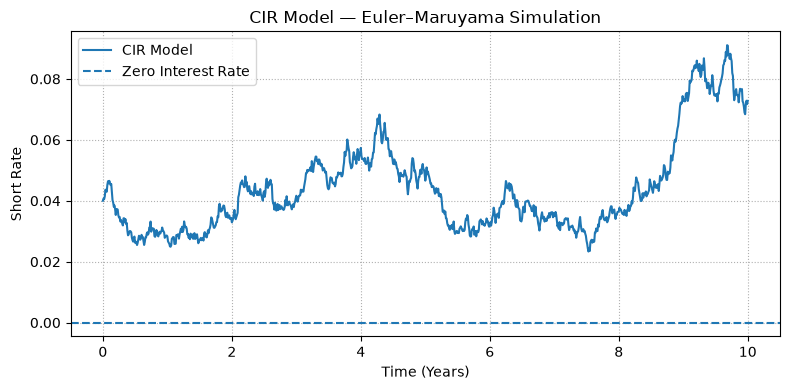

In [11]:
# Visualise the CIR path
plt.figure(figsize=(8,4))
plt.plot(t,r_cir,label="CIR Model")
plt.axhline(0,linestyle="--",label="Zero Interest Rate")
plt.title("CIR Model — Euler–Maruyama Simulation")
plt.xlabel("Time (Years)")
plt.ylabel("Short Rate")
plt.legend()
plt.grid(True, linestyle=":")
plt.tight_layout()
plt.show()

### ***Interpretation***

The simulated CIR path exhibits clear mean reversion toward the long-run interest rate of $b=5\%$. The short rate fluctuates around this level over
the 10-year horizon, while the magnitude of the fluctuations becomes smaller as the rate approaches zero because the diffusion term is proportional to
$\sqrt{r_t}$.

In this simulation, the short rate remains positive throughout the period and does not approach the zero boundary particularly closely.
This is consistent with the relatively moderate volatility used in the baseline specification. The behaviour contrasts with the Vasicek model, where the volatility is constant and the simulated rate can move below zero.

## 5.4 *Feller Condition*

The CIR model has a state-dependent volatility term, $\sigma\sqrt{r_t}$, which helps prevent the interest rate from becoming negative. A key
condition governing the behaviour of the process near the zero boundary is the Feller condition:

$$
2ab \geq \sigma^2.
$$

When the Feller condition is satisfied, the CIR process remains strictly positive. When it is violated, the process may reach the zero boundary.

For the baseline parameters used in this project,

$$
a=0.15,\qquad b=0.05,\qquad \sigma=0.07,
$$

the two sides of the condition are:

$$
2ab = 2(0.15)(0.05)=0.015
$$

and

$$
\sigma^2=(0.07)^2=0.0049.
$$

Therefore,

$$
2ab > \sigma^2,
$$

so the Feller condition is satisfied for the baseline specification.

In [12]:
# Check the Feller condition
feller_left = 2*a*b
feller_right = sigma**2

print(f"2ab = {feller_left:.6f}")
print(f"sigma^2 = {feller_right:.6f}")

if feller_left >= feller_right:
    print("Feller condition satisfied.")
else:
    print("Feller condition violated.")

2ab = 0.015000
sigma^2 = 0.004900
Feller condition satisfied.


The Feller condition can also be expressed as a restriction on volatility:

$$
\sigma \leq \sqrt{2ab}.
$$

This gives the maximum volatility consistent with the Feller condition for a given mean-reversion speed and long-run mean.

In [13]:
# Maximum volatility satisfying the Feller condition
sigma_critical = np.sqrt(2*a*b)
print(f"Critical volatility: {sigma_critical:.6f}")
print(f"Baseline volatility: {sigma:.6f}")

Critical volatility: 0.122474
Baseline volatility: 0.070000


### ***Interpretation***

The baseline CIR specification satisfies the Feller condition because $2ab=0.015$ is greater than $\sigma^2=0.0049$. The corresponding critical
volatility is approximately $\sigma=0.1225$, meaning that the baseline volatility of $0.07$ is comfortably below the level at which the Feller
condition becomes violated.

This provides a useful benchmark for the stress tests conducted earlier. Increasing volatility beyond the critical level causes the Feller condition
to be violated, increasing the likelihood that the process approaches the zero boundary. In the Euler–Maruyama implementation, sufficiently high
volatility can also produce negative interest rates, even though the theoretical CIR process itself remains non-negative.

## 5.5 *CIR Volatility Stress Test*

### 5.5.1 *Single-path stress test*

To examine the sensitivity of CIR to volatility, I simulate the model under several values of $\sigma$ while holding the other model parameters constant.

The volatility scenarios are:

$$
\sigma \in \{0.03,\ 0.05,\ 0.07,\ 0.10,\ 0.15,\ 0.20\}.
$$

The critical volatility implied by the Feller condition is approximately $\sigma=0.1225$. Therefore, the scenarios include both cases in which the
Feller condition is satisfied and cases in which it is violated.

For each volatility scenario, the simulated path is checked for the occurrence of at least one negative numerical rate. The minimum simulated rate is also recorded to examine how closely the process approaches the zero boundary.

In [14]:
# CIR volatility stress test
sigma_values = [0.03, 0.05, 0.07, 0.10, 0.15, 0.20]

# Generate common random shocks for all volatility scenarios
Z_stress = np.random.normal(0, 1, N)

# Store CIR simulations for each volatility scenario
cir_stress_results = {}

for sigma_test in sigma_values:
    r_cir_stress = np.zeros(N + 1)
    r_cir_stress[0] = r0

    for i in range(1, N + 1):
        r_cir_prev = max(r_cir_stress[i - 1], 0)
        dW = Z_stress[i - 1]*np.sqrt(dt)
        r_cir_stress[i] = (r_cir_stress[i - 1] + a*(b - r_cir_prev)*dt + sigma_test*np.sqrt(r_cir_prev)*dW)

    cir_stress_results[sigma_test] = r_cir_stress


# Calculate stress-test statistics
cir_negative = []
cir_minimum = []

for sigma_test in sigma_values:
    r_cir_stress = cir_stress_results[sigma_test]
    negative_rate = np.any(r_cir_stress < 0)
    minimum_rate = np.min(r_cir_stress)
    cir_negative.append(negative_rate)
    cir_minimum.append(minimum_rate)

print("Sigma    Feller Condition    Negative Rate?    Minimum Rate")

for i, sigma_test in enumerate(sigma_values):
    feller_satisfied = 2*a*b >= sigma_test**2
    status = "Satisfied" if feller_satisfied else "Violated"

    print(f"{sigma_test:<9.2f}"
        f"{status:<20}"
        f"{str(cir_negative[i]):<18}"
        f"{cir_minimum[i]:.6f}")

Sigma    Feller Condition    Negative Rate?    Minimum Rate
0.03     Satisfied           False             0.039147
0.05     Satisfied           False             0.034842
0.07     Satisfied           False             0.030312
0.10     Satisfied           False             0.023607
0.15     Violated            False             0.013253
0.20     Violated            False             0.001307


### ***Interpretation***
The stress test examines how increasing volatility affects the behaviour of the CIR model near the zero boundary.

The results show that the minimum simulated short rate decreases progressively as volatility increases, moving from approximately 3.91% at $\sigma=0.03$ to 0.13% at $\sigma=0.20$. This illustrates how higher volatility can bring the simulated rate increasingly close to the zero boundary.

For the scenarios in which the Feller condition is satisfied, the simulated path remains positive throughout the simulation. The condition is violated at volatility levels of 0.15 and 0.20. However, no negative numerical rates occur in either of these scenarios. This is not inconsistent with the theoretical implications of Feller violation, since violating the condition makes the zero boundary attainable but does not imply that every simulated path must reach it.

Overall, the results illustrate how increasing volatility affects the proximity of the CIR process to the zero boundary, while also highlighting the distinction between the theoretical boundary properties of the continuous-time process and the outcomes of individual numerical simulations.

### *Visualising Negative-Rate Occurrence in Single-Path CIR Stress Tests*

The occurrence of negative numerical rates is examined across individual CIR simulations under different volatility assumptions. Each observation represents a single simulated path rather than a probability estimate. The vertical line represents the critical volatility implied by the Feller condition.

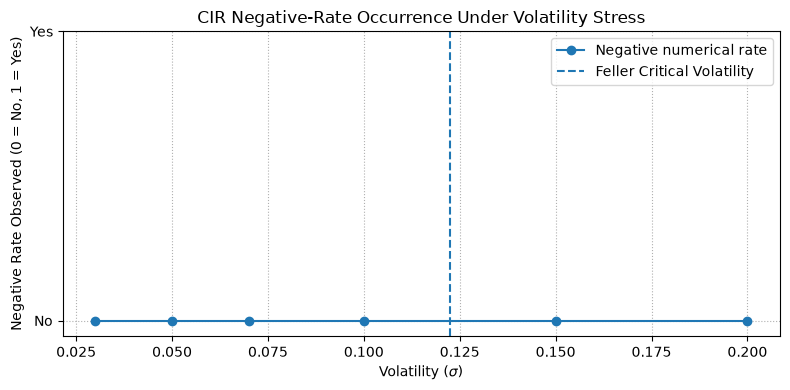

In [15]:
# Plot negative-rate occurrence under volatility stress
plt.figure(figsize=(8,4))
plt.plot(sigma_values,np.array(cir_negative, dtype=int),marker="o",label="Negative numerical rate")
plt.axvline(sigma_critical,linestyle="--",label="Feller Critical Volatility")
plt.xlabel(r"Volatility ($\sigma$)")
plt.ylabel("Negative Rate Observed (0 = No, 1 = Yes)")
plt.title("CIR Negative-Rate Occurrence Under Volatility Stress")
plt.yticks([0, 1], ["No", "Yes"])
plt.legend()
plt.grid(True, linestyle=":")
plt.tight_layout()
plt.show()

### 5.5.2 *Monte Carlo Stress Simulation*
To examine the distribution and tail behaviour of the two models under stress, 10,000 short-rate paths are simulated using the stressed volatility
of $\sigma=0.20$.

Both models use the same initial conditions, time horizon, and discretisation parameters. The resulting simulated paths are used in the subsequent distribution and tail-risk analysis.

In [16]:
# Monte Carlo stress simulation
# Stress scenario: sigma = 0.20
sigma_stress = 0.20
M = 10_000

# Generate standard normal shocks
Z_stress = np.random.normal(0, 1, size=(M, N))

# Initialise paths
r_vasicek_stress = np.zeros((M, N + 1))
r_cir_stress_mc = np.zeros((M, N + 1))

r_vasicek_stress[:, 0] = r0
r_cir_stress_mc[:, 0] = r0

# Euler–Maruyama simulation (partial-truncation scheme for CIR)
for i in range(1, N + 1):

    dW = Z_stress[:, i - 1] * np.sqrt(dt)

    # Vasicek
    r_vasicek_stress[:, i] = (r_vasicek_stress[:, i - 1] + a*(b - r_vasicek_stress[:, i - 1])*dt + sigma_stress*dW)

    # CIR
    r_cir_prev = np.maximum(r_cir_stress_mc[:, i - 1], 0)
    r_cir_stress_mc[:, i] = (r_cir_stress_mc[:, i - 1] + a*(b - r_cir_prev)*dt + sigma_stress*np.sqrt(r_cir_prev)*dW)

print("Monte Carlo stress simulation completed.")
print(f"Number of paths: {M:,}")
print(f"Stress volatility: {sigma_stress:.2%}")

Monte Carlo stress simulation completed.
Number of paths: 10,000
Stress volatility: 20.00%


### 5.5.3 Monte Carlo Negative-Rate Frequency
While the preceding stress test examines individual simulated paths, the Monte Carlo analysis evaluates negative-rate occurrence across 10,000 simulated paths.

For each model, the proportion of paths that experience at least one negative rate during the simulation horizon is calculated. The proportion of paths with negative terminal rates is also examined.

This provides a more informative assessment of negative-rate occurrence across the simulated sample. For the CIR model, any negative numerical realizations must be interpreted in the context of the partial-truncation Euler–Maruyama discretisation rather than as theoretical negative-rate outcomes.

In [17]:
# Negative-rate occurrence across Monte Carlo paths
vas_terminal = r_vasicek_stress[:, -1]
cir_terminal = r_cir_stress_mc[:, -1]

# Check whether each path produces a negative rate at any time
vas_negative_paths = np.any(r_vasicek_stress < 0, axis=1)
cir_negative_paths = np.any(r_cir_stress_mc < 0, axis=1)

# Calculate the proportion of paths with negative rates
vas_negative_frequency = np.mean(vas_negative_paths)
cir_negative_frequency = np.mean(cir_negative_paths)

# Check negative rates specifically at the terminal time
vas_terminal_negative = np.mean(vas_terminal < 0)
cir_terminal_negative = np.mean(cir_terminal < 0)

print("Negative-Rate Occurrence Across Monte Carlo Paths")
print(f"Number of simulated paths: {M:,}\n")

print("VASICEK")
print(f"Paths with at least one negative rate: "f"{vas_negative_frequency:.2%}")
print(f"Paths with negative terminal rates: "f"{vas_terminal_negative:.2%}")

print("\nCIR")
print(f"Paths with at least one negative numerical rate: "f"{cir_negative_frequency:.2%}")
print(f"Paths with negative terminal numerical rates: "f"{cir_terminal_negative:.2%}")

Negative-Rate Occurrence Across Monte Carlo Paths
Number of simulated paths: 10,000

VASICEK
Paths with at least one negative rate: 96.41%
Paths with negative terminal rates: 44.69%

CIR
Paths with at least one negative numerical rate: 76.76%
Paths with negative terminal numerical rates: 4.87%


## 6. *Distribution and Lower-Tail Analysis*

## 6.1 *Distribution of Terminal Short Rates*

To compare the range of outcomes generated by the two short-rate models, the distribution of the simulated short rate at the end of the 10-year horizon
is examined.
The terminal-rate distribution provides a way to compare the dispersion and tail behaviour of the Vasicek and CIR models under the stressed volatility scenario of $\sigma=0.20$.

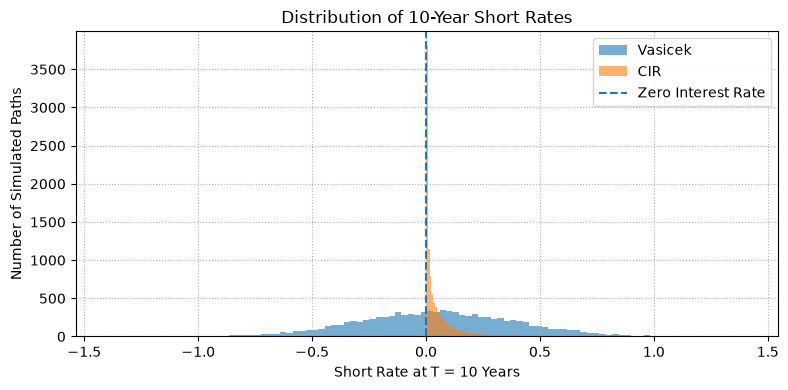

In [18]:
# Terminal short-rate distribution under the stressed case
plt.figure(figsize=(8,4))
plt.hist(vas_terminal,bins=100,alpha=0.6,label="Vasicek")
plt.hist(cir_terminal,bins=100,alpha=0.6,label="CIR")
plt.axvline(0,linestyle="--",linewidth=1.5,label="Zero Interest Rate")
plt.xlabel("Short Rate at T = 10 Years")
plt.ylabel("Number of Simulated Paths")
plt.title("Distribution of 10-Year Short Rates")
plt.legend()
plt.grid(True, linestyle=":")
plt.tight_layout()
plt.show()

### *Interpretation*

The stressed simulation shows a substantial difference between the terminal short-rate distributions of the two models. The Vasicek distribution is much more dispersed and has a pronounced lower tail extending into highly negative rates, while the CIR distribution is considerably more concentrated around the positive range.

This difference arises from the models' treatment of volatility. Vasicek uses a constant diffusion term, allowing random shocks to push the short rate arbitrarily far below zero. CIR instead uses the state-dependent term $\sigma\sqrt{r_t}$, which reduces the magnitude of the diffusion component as the short rate approaches zero.

The results therefore illustrate how the structural assumptions of a short-rate model can materially affect the distribution of simulated interest rates, particularly under stressed volatility.

### 6.1.1 *Terminal-Rate Summary Statistics*

In [19]:
print("=== STRESSED CASE: σ = 0.20 ===\n")
print("VASICEK")
print(f"Mean:            {np.mean(vas_terminal):.4%}")
print(f"Standard deviation: {np.std(vas_terminal):.4%}")
print(f"Minimum:         {np.min(vas_terminal):.4%}")
print(f"Maximum:         {np.max(vas_terminal):.4%}")
print(f"5th percentile:  {np.percentile(vas_terminal, 5):.4%}")
print(f"95th percentile: {np.percentile(vas_terminal, 95):.4%}")

print("\nCIR")
print(f"Mean:            {np.mean(cir_terminal):.4%}")
print(f"Standard deviation: {np.std(cir_terminal):.4%}")
print(f"Minimum:         {np.min(cir_terminal):.4%}")
print(f"Maximum:         {np.max(cir_terminal):.4%}")
print(f"5th percentile:  {np.percentile(cir_terminal, 5):.4%}")
print(f"95th percentile: {np.percentile(cir_terminal, 95):.4%}")

=== STRESSED CASE: σ = 0.20 ===

VASICEK
Mean:            4.6674%
Standard deviation: 34.7975%
Minimum:         -139.7720%
Maximum:         140.5587%
5th percentile:  -51.8374%
95th percentile: 62.0976%

CIR
Mean:            4.6541%
Standard deviation: 7.4353%
Minimum:         -0.0857%
Maximum:         83.0438%
5th percentile:  0.0003%
95th percentile: 19.5031%


### ***Interpretation***
The summary statistics reinforce the differences observed in the terminal-rate distributions. Under the stressed volatility assumption of $\sigma=0.20$, the Vasicek model produces substantially greater dispersion than the CIR model, with a much wider range between its minimum and maximum values.

The Vasicek distribution extends considerably into negative territory. The CIR distribution is more concentrated around positive rates, with its 5th percentile lying very close to zero. However, its minimum simulated terminal rate is approximately -0.0857%, demonstrating that the partial-truncation Euler–Maruyama scheme can produce small negative numerical values under sufficiently stressed conditions.

Although the theoretical CIR process remains non-negative, the numerical implementation does not guarantee this property. The negative realizations therefore reflect a limitation of the discretization rather than a theoretical feature of the CIR model.

## 6.2 *Lower-Tail Analysis*

To examine the lower tail of the terminal short-rate distributions, the 1st and 5th percentiles are calculated for both models.

These percentiles indicate the levels below which only 1% and 5% of simulated terminal short rates fall, respectively. They provide a clearer view of the downside behaviour of each model under the stressed volatility scenario.

In [20]:
# Calculate lower-tail percentiles

vas_1pct = np.percentile(vas_terminal, 1)
vas_5pct = np.percentile(vas_terminal, 5)

cir_1pct = np.percentile(cir_terminal, 1)
cir_5pct = np.percentile(cir_terminal, 5)

print("Vasicek 1st percentile:", vas_1pct)
print("Vasicek 5th percentile:", vas_5pct)
print("CIR 1st percentile:", cir_1pct)
print("CIR 5th percentile:", cir_5pct)

Vasicek 1st percentile: -0.7679423295716219
Vasicek 5th percentile: -0.5183735501319706
CIR 1st percentile: -0.00025234794076631906
CIR 5th percentile: 2.5032293556373642e-06


### ***Interpretation***

The lower-tail percentiles highlight differences in the lower-tail characteristics of the two models under stressed volatility scenario. The Vasicek model exhibits a substantially wider lower tail, while the CIR model remains concentrated near zero.

The results illustrate that the Vasicek model can generate substantially more extreme negative terminal rates under high volatility. The theoretical CIR process, by contrast, remains non-negative. However, the partial-truncation Euler–Maruyama implementation can produce small negative numerical values near the zero boundary. This reflects a limitation of the discretization rather than the theoretical model.

## 6.3 *Lower-Tail Analysis of Terminal Short Rates*

To further examine the lower-tail behaviour of the terminal short-rate distributions, the average of the lowest 5% of simulated terminal rates is calculated for each model.

The 5th percentile is used as the threshold, and the mean of observations at or below this threshold is calculated. This statistic complements the percentile analysis by providing information about the average level of rates within the lower tail of each simulated distribution.

The measure is used here as a descriptive statistic of the simulated interest-rate distributions rather than as a financial loss measure.

In [21]:
# Calculate mean of the lowest 5% of terminal short rates
vas_threshold = np.percentile(vas_terminal, 5)
cir_threshold = np.percentile(cir_terminal, 5)

vas_lower_tail_mean = vas_terminal[vas_terminal <= vas_threshold].mean()
cir_lower_tail_mean = cir_terminal[cir_terminal <= cir_threshold].mean()

print("Vasicek 5th percentile:", vas_threshold)
print("Vasicek mean of lowest 5%:", vas_lower_tail_mean)

print("\nCIR 5th percentile:", cir_threshold)
print("CIR mean of lowest 5%:", cir_lower_tail_mean)

Vasicek 5th percentile: -0.5183735501319706
Vasicek mean of lowest 5%: -0.672065215842792

CIR 5th percentile: 2.5032293556373642e-06
CIR mean of lowest 5%: -0.00014717484925495328


### ***Interpretation***
The mean of the lowest 5% of terminal short rates gives us additional information about the lower-tail characteristics of the simulated distributions.

The Vasicek model exhibits a substantially lower average rate within this portion of its distribution than the CIR model under the stressed volatility scenario. This reflects the greater dispersion of  Gaussian structure of the Vasicek model.

The CIR model exhibits a more concentrated lower tail because its diffusion coefficient is state-dependent and diminishes as the short rate approaches zero. Small negative numerical values may nevertheless occur because of the partial-truncation Euler–Maruyama discretisation.

## *Applied Quantitative Finance*

## 7.1 *Zero-Coupon Bond Valuation*

The simulated short-rate paths can be used to construct a pathwise discount factor over the investment horizon.

For a continuously compounded short-rate process, the discount factor along a simulated path is:

$$
D(0,T) = \exp\left(-\int_0^T r_t\,dt\right)
$$

Using the simulated rate paths, the integral is approximated numerically as:

$$
\int_0^T r_t\,dt \approx \sum_{i=0}^{N-1} r_{t_i}\Delta t
$$

The resulting discount factors can be interpreted as simulated model-implied zero-coupon bond prices for a bond with a face value of $1 under the assumed short-rate dynamics.

In [22]:
# Calculating pathwise zero-coupon bond discount factors
vas_integral = np.sum(r_vasicek_stress[:, :-1]*dt, axis=1)
cir_integral = np.sum(r_cir_stress_mc[:, :-1]*dt, axis=1)

vas_discount_factors = np.exp(-vas_integral)
cir_discount_factors = np.exp(-cir_integral)

print("Vasicek mean discount factor:", np.mean(vas_discount_factors))
print("CIR mean discount factor:", np.mean(cir_discount_factors))

print("Vasicek minimum discount factor:", np.min(vas_discount_factors))
print("Vasicek maximum discount factor:", np.max(vas_discount_factors))

print("CIR minimum discount factor:", np.min(cir_discount_factors))
print("CIR maximum discount factor:", np.max(cir_discount_factors))

Vasicek mean discount factor: 7.5179935076701705
CIR mean discount factor: 0.6918288544978077
Vasicek minimum discount factor: 9.583257770626251e-05
Vasicek maximum discount factor: 4994.3685865362595
CIR minimum discount factor: 0.005675793151942957
CIR maximum discount factor: 0.9816604052751047


### ***Interpretation***
The discount-factor results translate the differences in the simulated short-rate distributions into fixed-income valuation consequences.

Because the discount factor depends exponentially on the accumulated short rate, extreme rate paths can produce disproportionately large valuation effects. The Vasicek model is particularly sensitive under the stressed volatility scenario because its Gaussian structure permits very large positive and negative rates, whereas the CIR model produces substantially more constrained outcomes.

The resulting differences illustrate how assumptions about interest-rate dynamics can have significant implications for bond valuation and model risk.

### 7.1.1 Analytical Benchmark for Vasicek Bond Pricing

The Vasicek model admits a closed-form expression for zero-coupon bond prices. This provides an independent benchmark against which the Monte Carlo valuation can be assessed.

Under the risk-neutral Vasicek model, the theoretical zero-coupon bond price is:

$$
P(0,T)=A(0,T)e^{-B(0,T)r_0}
$$

where:

$$
B(0,T)=\frac{1-e^{-aT}}{a}
$$

and:

$$
A(0,T)=
\exp\left[
\left(b-\frac{\sigma^2}{2a^2}\right)(B(0,T)-T)
-\frac{\sigma^2B(0,T)^2}{4a}
\right].
$$

The analytical price is calculated using the same model parameters and stressed volatility assumption as the Monte Carlo simulation. The two estimates are then compared to assess the accuracy of the numerical valuation.

In [23]:
# Analytical Vasicek zero-coupon bond price

B_vas = (1 - np.exp(-a*T))/a
A_vas = np.exp((b - sigma_stress**2/(2*a**2))*(B_vas - T) - (sigma_stress**2*B_vas**2)/(4*a))
vas_analytical_price = A_vas*np.exp(-B_vas*r0)

# Monte Carlo estimate
vas_mc_price = np.mean(vas_discount_factors)

# Monte Carlo standard error
vas_mc_se = np.std(vas_discount_factors, ddof=1)/np.sqrt(M)

# Difference between the two estimates
vas_pricing_error = vas_mc_price - vas_analytical_price

print("Vasicek Analytical Bond Price:", vas_analytical_price)
print("Vasicek Monte Carlo Bond Price:", vas_mc_price)
print("Monte Carlo Standard Error:", vas_mc_se)
print("Monte Carlo Pricing Difference:", vas_pricing_error)
print("Absolute Pricing Difference:", abs(vas_pricing_error))

Vasicek Analytical Bond Price: 7.758427600079974
Vasicek Monte Carlo Bond Price: 7.5179935076701705
Monte Carlo Standard Error: 0.7487796241798894
Monte Carlo Pricing Difference: -0.24043409240980385
Absolute Pricing Difference: 0.24043409240980385


In [24]:
# Standardised pricing difference
vas_z_score = vas_pricing_error/vas_mc_se

print("Standardised Pricing Difference:", vas_z_score)

Standardised Pricing Difference: -0.3211012755230117


### Interpretation

The analytical Vasicek bond price provides a theoretical benchmark for evaluating the Monte Carlo valuation. Both estimates use the same initial short rate, model parameters, maturity, and stressed volatility assumption.

The absolute difference between the Monte Carlo estimate and the analytical benchmark is approximately 0.32 standard errors. This indicates reasonable agreement between the two estimates relative to the estimated sampling uncertainty. However, given the highly right-skewed distribution of simulated discount factors, the standard error should be interpreted cautiously.

## 7.2 *Bond-Price Distribution*

The pathwise discount factors from Section 7.1 can be interpreted as zero-coupon bond prices for a bond with a face value of $1.

The distribution of these simulated prices provides a clearer view of the valuation uncertainty generated by each interest-rate model under the stressed volatility scenario.

Because bond prices are an exponential function of accumulated short rates, extreme interest-rate realizations can translate into highly skewed bond-price distributions, particularly for the Vasicek model under high volatility.

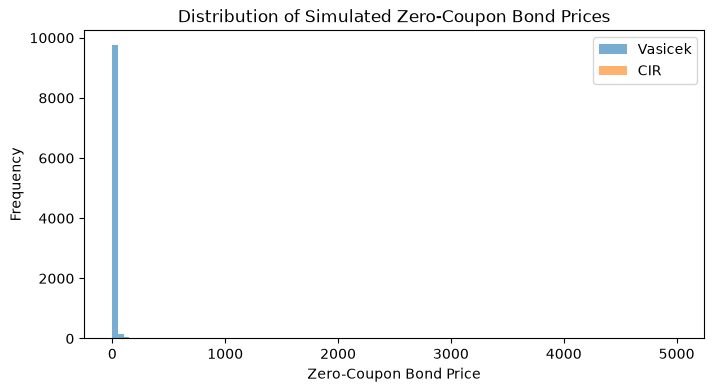

In [25]:
# Plotting the distribution of simulated zero-coupon bond prices
plt.figure(figsize=(8,4))
plt.hist(vas_discount_factors,bins=100,alpha=0.6,label="Vasicek")
plt.hist(cir_discount_factors,bins=100,alpha=0.6,label="CIR")
plt.xlabel("Zero-Coupon Bond Price")
plt.ylabel("Frequency")
plt.title("Distribution of Simulated Zero-Coupon Bond Prices")
plt.legend()
plt.show()

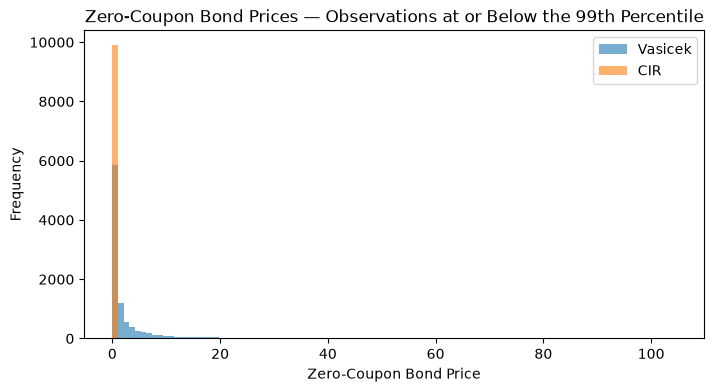

In [26]:
# Plotting the central 99% of the simulated bond-price distributions
vas_upper = np.percentile(vas_discount_factors, 99)
cir_upper = np.percentile(cir_discount_factors, 99)

vas_central = vas_discount_factors[vas_discount_factors <= vas_upper]
cir_central = cir_discount_factors[cir_discount_factors <= cir_upper]

upper_bound = max(vas_upper, cir_upper)
bins = np.linspace(0, upper_bound, 101)

plt.figure(figsize=(8,4))
plt.hist(vas_central,bins=bins,alpha=0.6,label="Vasicek")
plt.hist(cir_central,bins=bins,alpha=0.6,label="CIR")
plt.xlabel("Zero-Coupon Bond Price")
plt.ylabel("Frequency")
plt.title("Zero-Coupon Bond Prices — Observations at or Below the 99th Percentile")
plt.legend()
plt.show()
# This plot excludes observations above the 99th percentile
# for visual clarity; the original data remain unchanged.

### **Interpretation**

The bond-price distributions demonstrate how differences in the short-rate models affects fixed-income valuation.

The Vasicek distribution is substantially more dispersed and strongly influenced by extreme observations, while the CIR distribution is considerably more concentrated. This reflects the wider range of interest-rate outcomes generated by the Gaussian Vasicek model under the stressed volatility assumption.

## 7.3 *Bond-Price Risk Summary*

To quantify the dispersion and tail behaviour of the simulated zero-coupon bond prices, several summary statistics are calculated for each model.

- Mean bond price
- Standard deviation
- 5th percentile
- 95th percentile
- Minimum and maximum bond prices

These measures provide a numerical comparison of the valuation dispersion and tail behaviour produced by the Vasicek and CIR models under the stressed volatility scenario.

In [27]:
# Calculating bond-price risk metrics
vas_bond_metrics = { "Mean": np.mean(vas_discount_factors),"Median": np.median(vas_discount_factors),
                     "Standard Deviation": np.std(vas_discount_factors),"5th Percentile": np.percentile(vas_discount_factors, 5),
                     "95th Percentile": np.percentile(vas_discount_factors, 95),"Minimum": np.min(vas_discount_factors),
                     "Maximum": np.max(vas_discount_factors)}

cir_bond_metrics = {"Mean": np.mean(cir_discount_factors),"Median": np.median(cir_discount_factors),"Standard Deviation": np.std(cir_discount_factors),
    "5th Percentile": np.percentile(cir_discount_factors, 5),"95th Percentile": np.percentile(cir_discount_factors, 95),
                    "Minimum": np.min(cir_discount_factors),"Maximum": np.max(cir_discount_factors)}

print("Vasicek Bond-Price Risk Metrics")
for metric, value in vas_bond_metrics.items():
    print(f"{metric}: {value:.6f}")

print("\nCIR Bond-Price Risk Metrics")
for metric, value in cir_bond_metrics.items():
    print(f"{metric}: {value:.6f}")

Vasicek Bond-Price Risk Metrics
Mean: 7.517994
Median: 0.644788
Standard Deviation: 74.874218
5th Percentile: 0.016678
95th Percentile: 24.953111
Minimum: 0.000096
Maximum: 4994.368587

CIR Bond-Price Risk Metrics
Mean: 0.691829
Median: 0.754205
Standard Deviation: 0.214783
5th Percentile: 0.250446
95th Percentile: 0.935257
Minimum: 0.005676
Maximum: 0.981660


### ***Interpretation***

The risk metrics confirm that the Vasicek model generates substantially greater bond-price dispersion under the stressed volatility scenario. Its wider range and larger standard deviation reflect the model's ability to generate extreme positive and negative short-rate realizations, which are amplified through the exponential discounting relationship.

The CIR model is generally less sensitive to extreme bond-price outcomes because its volatility is state-dependent and declines as the short rate approaches zero. However, its valuation risk also increases as volatility rises, particularly when the Feller condition is violated.

## 7.4 *Volatility Sensitivity*

To examine how interest-rate volatility affects bond valuation, the simulation is repeated across a range of volatility assumptions.

The same underlying standard-normal random shocks are used for each volatility scenario. This common-random-number approach helps isolate the effect of changing volatility by reducing differences caused by random sampling.

For each volatility level, the mean and standard deviation of the simulated zero-coupon bond prices are calculated for both the Vasicek and CIR models.

In [28]:
# Volatility sensitivity analysis
sigma_values = np.array([0.03, 0.05, 0.07, 0.10, 0.15, 0.20])

# Common random shocks for all volatility scenarios
Z_vol = np.random.normal(0, 1, size=(M, N))

vas_mean_prices = []
vas_std_prices = []
vas_median_prices = []


cir_mean_prices = []
cir_std_prices = []
cir_median_prices = []

for sigma_test in sigma_values:
    # Initialise rates and accumulated short-rate integrals
    r_v = np.full(M, r0)
    r_c = np.full(M, r0)

    vas_integral = np.zeros(M)
    cir_integral = np.zeros(M)

    for i in range(N):
        dW = Z_vol[:, i]*np.sqrt(dt)
        
        # Vasicek
        vas_integral += r_v*dt
        r_v = r_v + a*(b - r_v)*dt + sigma_test*dW

        # CIR
        # CIR
        cir_integral += r_c*dt
        r_c_prev = np.maximum(r_c, 0)
        r_c = (r_c + a*(b - r_c_prev)*dt + sigma_test*np.sqrt(r_c_prev)*dW)

    # Calculate zero-coupon bond prices
    vas_prices = np.exp(-vas_integral)
    cir_prices = np.exp(-cir_integral)

    # Store risk metrics
    vas_mean_prices.append(np.mean(vas_prices))
    vas_std_prices.append(np.std(vas_prices))
    vas_median_prices.append(np.median(vas_prices))


    cir_mean_prices.append(np.mean(cir_prices))
    cir_std_prices.append(np.std(cir_prices))
    cir_median_prices.append(np.median(cir_prices))

In [29]:
# Printing volatility sensitivity results
print("Volatility | Vasicek Mean |Vasicek Median | Vasicek Std | CIR Mean |CIR Median | CIR Std")

for i, sigma_test in enumerate(sigma_values):
    print(f"{sigma_test:>9.2f}  | "
        f"{vas_mean_prices[i]:>12.4f} | "
        f"{vas_median_prices[i]:>11.4f}   | "
        f"{vas_std_prices[i]:>11.4f} | "
        f"{cir_mean_prices[i]:>8.4f} | "
        f"{cir_median_prices[i]:>8.4f}  | "
        f"{cir_std_prices[i]:>7.4f}   |")

Volatility | Vasicek Mean |Vasicek Median | Vasicek Std | CIR Mean |CIR Median | CIR Std
     0.03  |       0.6764 |      0.6379   |      0.2333 |   0.6405 |   0.6414  |  0.0440   |
     0.05  |       0.7480 |      0.6372   |      0.4522 |   0.6433 |   0.6463  |  0.0721   |
     0.07  |       0.8695 |      0.6366   |      0.7921 |   0.6473 |   0.6538  |  0.0985   |
     0.10  |       1.1960 |      0.6357   |      1.8040 |   0.6552 |   0.6701  |  0.1340   |
     0.15  |       2.5856 |      0.6342   |      7.9558 |   0.6724 |   0.7092  |  0.1807   |
     0.20  |       7.3343 |      0.6326   |     41.0216 |   0.6926 |   0.7537  |  0.2133   |


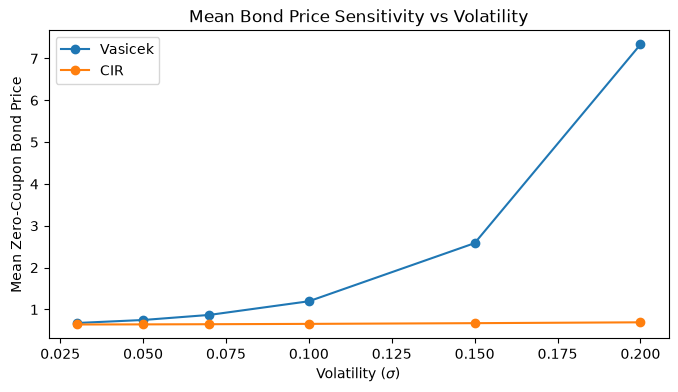

In [30]:
# Plotting mean bond price across volatility levels
plt.figure(figsize=(8,4))
plt.plot(sigma_values, vas_mean_prices, marker="o", label="Vasicek")
plt.plot(sigma_values, cir_mean_prices, marker="o", label="CIR")
plt.xlabel("Volatility ($\\sigma$)")
plt.ylabel("Mean Zero-Coupon Bond Price")
plt.title("Mean Bond Price Sensitivity vs Volatility")
plt.legend()
plt.show()

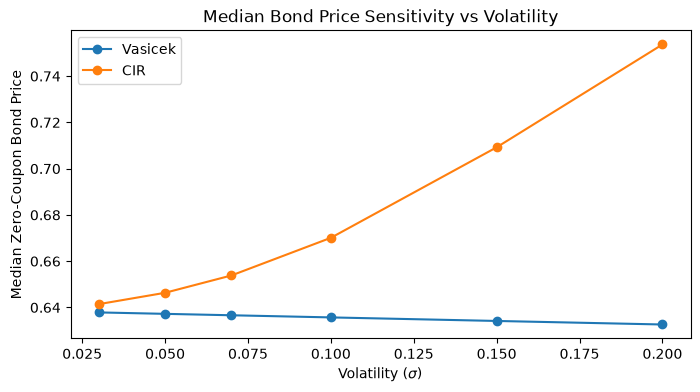

In [31]:
# Plotting median bond price across volatility levels
plt.figure(figsize=(8,4))
plt.plot(sigma_values, vas_median_prices, marker="o", label="Vasicek")
plt.plot(sigma_values, cir_median_prices, marker="o", label="CIR")
plt.xlabel("Volatility ($\\sigma$)")
plt.ylabel("Median Zero-Coupon Bond Price")
plt.title("Median Bond Price Sensitivity vs Volatility")
plt.legend()
plt.show()

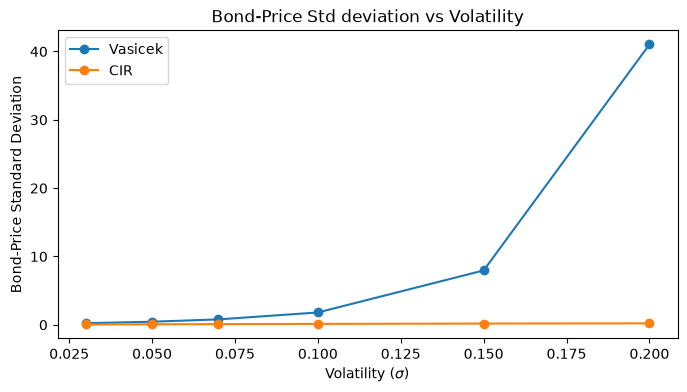

In [32]:
# Plotting bond-price standard deviation across volatility levels
plt.figure(figsize=(8,4))
plt.plot(sigma_values, vas_std_prices, marker="o", label="Vasicek")
plt.plot(sigma_values, cir_std_prices, marker="o", label="CIR")
plt.xlabel("Volatility ($\\sigma$)")
plt.ylabel("Bond-Price Standard Deviation")
plt.title("Bond-Price Std deviation vs Volatility")
plt.legend()
plt.show()

### ***Interpretation***

The volatility sensitivity analysis shows how increasing interest-rate volatility affects both the level and dispersion of simulated bond prices.

The Vasicek model becomes increasingly sensitive to volatility, with substantially greater bond-price dispersion at higher values of $\sigma$. This reflects the model's unrestricted Gaussian dynamics, which permit increasingly extreme short-rate realizations.

The CIR model is generally less sensitive to extreme bond-price outcomes because its volatility is state-dependent and declines as the short rate approaches zero. However, its valuation risk also increases as volatility rises, particularly when the Feller condition is violated.

Overall, the results demonstrate that volatility assumptions can materially influence both bond valuation and model risk.

## 7.5 *Stress-Test Summary*

The stress-testing results are summarised by comparing the behaviour of the Vasicek and CIR models across the different volatility scenarios.

The analysis focuses on how changes in volatility affect simulated interest rates and the resulting zero-coupon bond prices. Particular attention is given to dispersion, tail behaviour, and the increasingly pronounced differences between the two models as volatility rises.

In [33]:
# Create a summary of the volatility stress test
stress_summary = pd.DataFrame({"Sigma": sigma_values,"Vasicek Mean Price": vas_mean_prices,"Vasicek Median Price": vas_median_prices,
                               "Vasicek Price Std": vas_std_prices,"CIR Mean Price": cir_mean_prices,"CIR Median Price": cir_median_prices,
                               "CIR Price Std": cir_std_prices})
stress_summary

,Sigma,Vasicek Mean Price,Vasicek Median Price,Vasicek Price Std,CIR Mean Price,CIR Median Price,CIR Price Std
0,0.03,0.676419,0.637856,0.233250,0.640474,0.641434,0.044024
1,0.05,0.747986,0.637240,0.452229,0.643263,0.646344,0.072141
2,0.07,0.869507,0.636624,0.792078,0.647264,0.653833,0.098546
3,0.10,1.196016,0.635701,1.804049,0.655217,0.670110,0.134002
4,0.15,2.585584,0.634166,7.955780,0.672393,0.709233,0.180723
5,0.20,7.334343,0.632635,41.021591,0.692554,0.753671,0.213322


### ***Interpretation***
The stress-test results show that the choice of interest-rate model becomes increasingly important as volatility increases.

The Vasicek model exhibits substantially greater bond-price dispersion under higher volatility, reflecting its unrestricted Gaussian distribution and ability to generate extreme short-rate outcomes. The CIR model produces more constrained outcomes because its volatility is state-dependent and declines as the short rate approaches zero.

The results demonstrate that model assumptions about volatility dynamics and boundary behaviour can materially affect both valuation outcomes and the assessment of interest-rate model risk.

## 8. *Model Risk Assessment & Conclusion*

## 8.1 ***Key Findings***
The analysis showed several important differences between the Vasicek and CIR short-rate models.

1. The Vasicek model provides an analytically tractable mean-reverting framework, but its Gaussian structure permits interest rates to take arbitrarily large positive or negative values.

2. The CIR model introduces state-dependent volatility through the square-root diffusion term. This produces substantially more constrained behaviour near zero and provides a theoretical non-negativity property.

3. Under the stressed volatility scenario, the Vasicek model generated substantially greater dispersion and more extreme lower-tail outcomes than the CIR model.

4. The stress tests demonstrated that increasing volatility amplifies differences between the two models, particularly in the distribution of simulated interest rates and resulting bond prices.

5. These differences propagate directly into fixed-income valuation because bond discount factors depend exponentially on the accumulated short rate along each simulated path.

## 8.2 ***Model Risk Assessment***
The results demonstrate that interest-rate model selection can materially influence valuation and the assessment of model risk.

The primary model-risk concern identified for the Vasicek model is its unrestricted Gaussian distribution. While negative interest rates are mathematically possible within the model and may be economically plausible in some environments, sufficiently large volatility assumptions can produce extreme rate realizations that lead to potentially implausible valuation outcomes.

The CIR model addresses an important structural limitation by incorporating state-dependent volatility. The Feller condition determines whether the zero boundary is attainable under the standard CIR process. However, the partial-truncation Euler–Maruyama implementation does not guarantee non-negative numerical rates, and small negative values may arise near the zero boundary. Such values should be recognised as numerical discretization artefacts rather than as theoretical negative-rate outcomes of the CIR process.

The analysis therefore illustrates an important principle of quantitative model validation: a model should not be assessed solely on the basis of whether its equations are mathematically valid. Its assumptions, boundary behaviour, numerical implementation, and behaviour under stress must also be evaluated.

## 8.3 ***Conclusion***
This project compared the Vasicek and CIR short-rate models through stochastic simulation, numerical error analysis, convergence testing, volatility stress testing, lower-tail analysis, and zero-coupon bond valuation.

The Vasicek model demonstrated analytical tractability and close agreement between its Euler–Maruyama approximation and exact solution for the selected parameterization. However, its unrestricted Gaussian structure produced substantially more extreme interest-rate and bond-price outcomes under stressed volatility.

The CIR model produced more constrained interest-rate dynamics and substantially narrower valuation distributions. Its state-dependent volatility and theoretical non-negativity property provide an important distinction from the Vasicek model. The numerical simulations also highlighted the limitations of the partial-truncation Euler–Maruyama scheme near the zero boundary.

Overall, the results show that assumptions about volatility, mean reversion, and boundary behaviour can materially affect interest-rate distributions and fixed-income valuation. The comparison demonstrates why model structure, numerical implementation, and model validation are central considerations in quantitative interest-rate modelling and risk management.